In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df = pd.read_csv('Sample - Superstore.csv', encoding = 'windows-1252') 
df['Order Date'] = pd.to_datetime(df['Order Date'], format = '%m/%d/%Y')
df['MonthYear'] = df['Order Date'].dt.to_period('M')

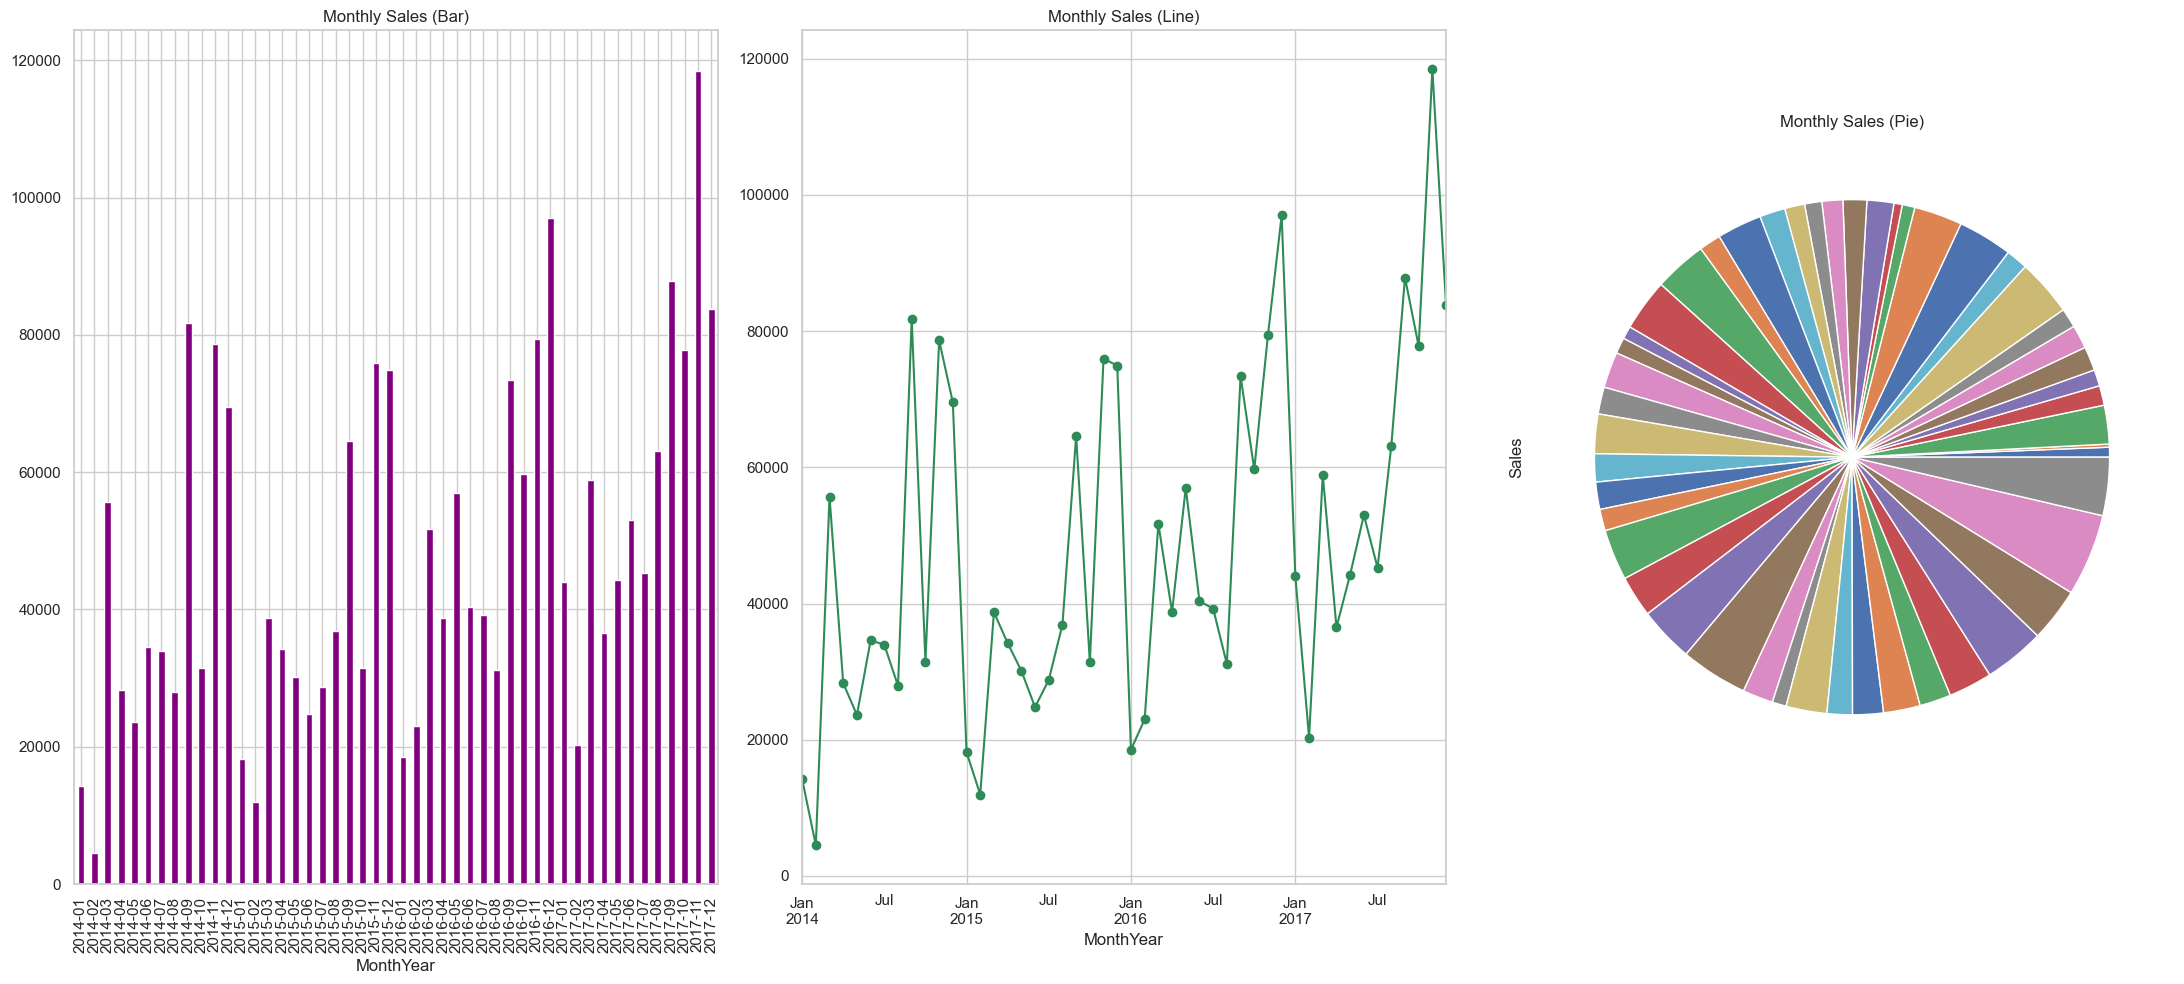

In [18]:
### TASK 1 ###
monthlySales = df.groupby('MonthYear')['Sales'].sum()
fig, axes = plt.subplots(1, 3, figsize = (22, 10))

monthlySales.plot(kind = 'bar', ax = axes[0], color = 'purple', title = 'Monthly Sales (Bar)')
monthlySales.plot(kind = 'line', ax = axes[1], color = 'seagreen', marker = 'o', title = 'Monthly Sales (Line)')
monthlySales.plot(kind = 'pie', ax = axes[2], labels = None, title = 'Monthly Sales (Pie)') 

plt.tight_layout()
plt.show()

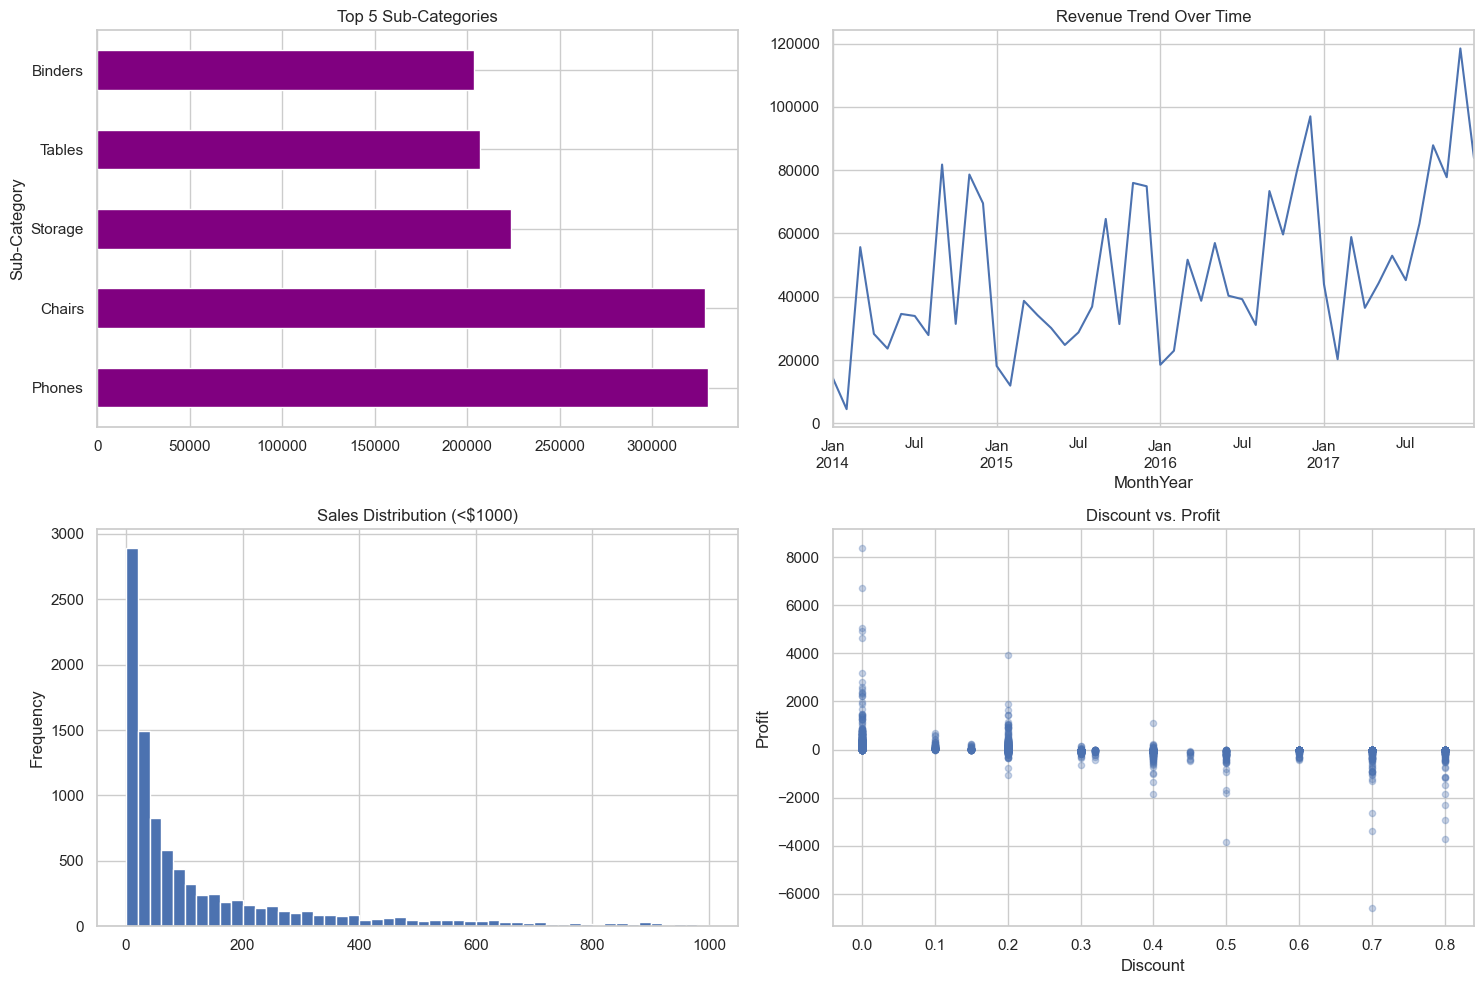

In [19]:
### TASK 2 ###
fig, axes = plt.subplots(2, 2, figsize = (15,10))
df.groupby('Sub-Category')['Sales'].sum().nlargest(5).plot(kind = 'barh', ax = axes[0,0], color = 'purple', title = 'Top 5 Sub-Categories')

monthlySales.plot(kind = 'line', ax = axes[0, 1], title = 'Revenue Trend Over Time')

df[df['Sales'] < 1000]['Sales'].plot(kind = 'hist', bins = 50, ax = axes[1, 0], title = 'Sales Distribution (<$1000)')

df.plot(kind = 'scatter', x = 'Discount', y = 'Profit', alpha = 0.3, ax = axes[1, 1], title = 'Discount vs. Profit')
plt.tight_layout()
plt.show()

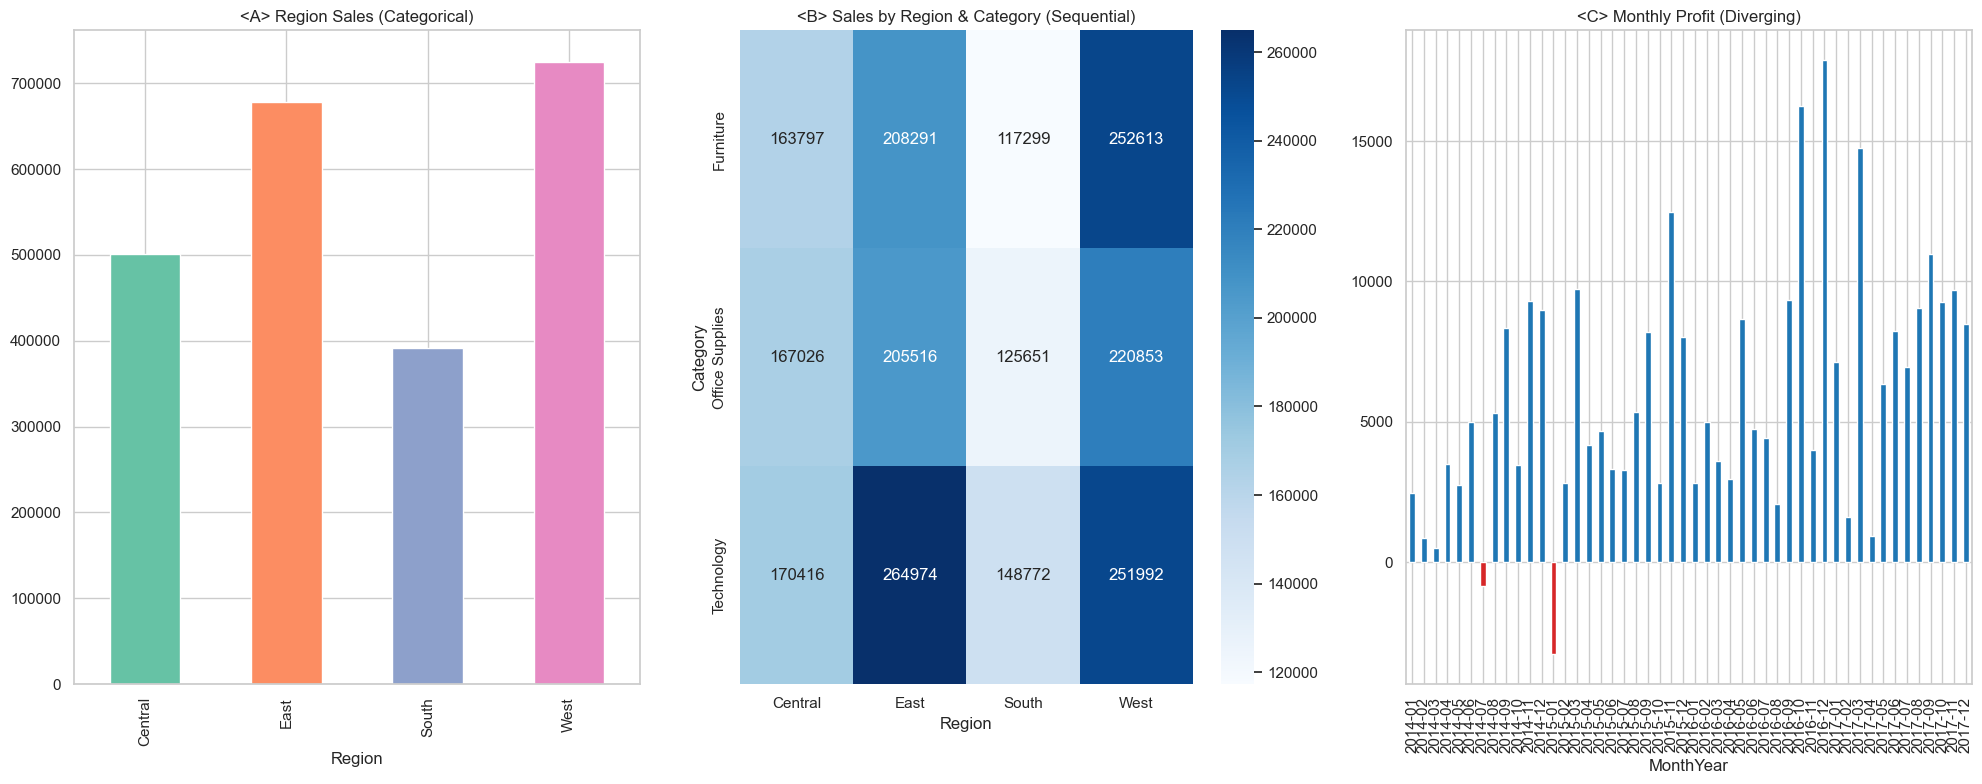

In [21]:
### TASK 3 ###
fig, axes = plt.subplots(1, 3, figsize = (20, 8))

cat_colors = sns.color_palette("Set2")
df.groupby('Region')['Sales'].sum().plot(kind = 'bar', color = cat_colors, ax = axes[0], title = '<A> Region Sales (Categorical)')

reg_cat = pd.crosstab(df['Category'], df['Region'], values = df['Sales'], aggfunc = 'sum')
sns.heatmap(reg_cat, cmap = 'Blues', annot = True, fmt = '.0f', ax = axes[1])
axes[1].set_title('<B> Sales by Region & Category (Sequential)')

monthly_profit = df.groupby('MonthYear')['Profit'].sum()
div_colors = ['#1f77b4' if val > 0 else '#d62728' for val in monthly_profit]
monthly_profit.plot(kind = 'bar', color = div_colors, ax = axes[2], title = '<C> Monthly Profit (Diverging)')

plt.tight_layout()
plt.show()

Contrast Ratios (Aim for >4.5):
Color [102, 194, 165]: 2.14:1
Color [252, 141, 98]: 2.30:1
Color [141, 160, 203]: 2.62:1


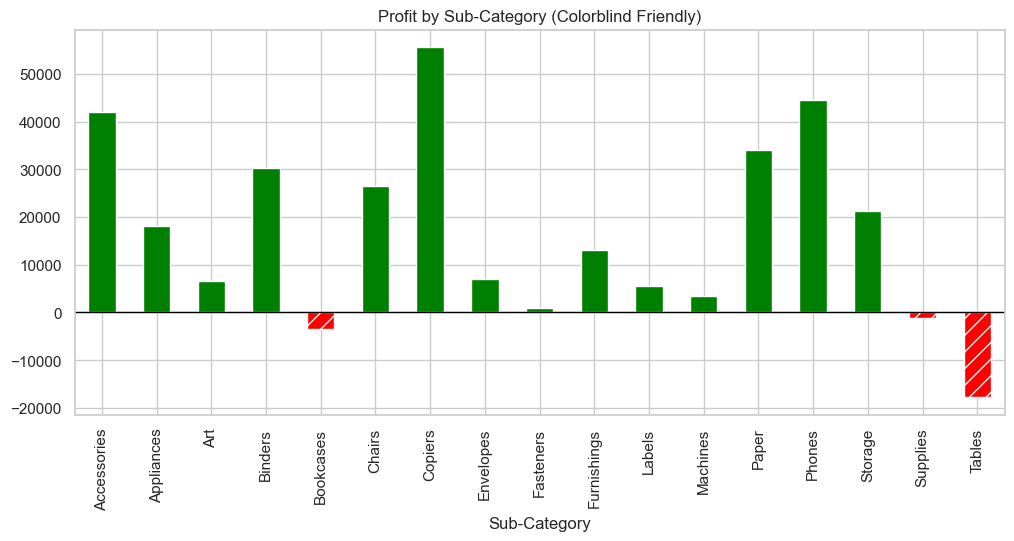

In [26]:
### TASK 4 ###
def get_contrast(rgb1, rgb2 = [255, 255, 255]):
    def luminance(c):
        c = [x / 255.0 for x in c]
        c = [x / 12.92 if x <= 0.03928 else ((x + 0.055) / 1.055)**2.4 for x in c]
        return 0.2126*c[0] + 0.7152*c[1] + 0.0722*c[2]
    
    l1, l2 = luminance(rgb1), luminance(rgb2)
    return (max(l1, l2) + 0.05) / (min(l1, l2) + 0.05)

print("Contrast Ratios (Aim for >4.5):")
for rgb in [[102,194,165], [252,141,98], [141,160,203]]: 
    print(f"Color {rgb}: {get_contrast(rgb):.2f}:1")

profit_sub = df.groupby('Sub-Category')['Profit'].sum()
ax = profit_sub.plot(kind = 'bar', figsize = (12, 5), title = 'Profit by Sub-Category (Colorblind Friendly)')

for patch, val in zip(ax.patches, profit_sub):
    patch.set_facecolor('green' if val > 0 else 'red')
    if val < 0:
        patch.set_hatch('//') 

plt.axhline(0, color = 'black', linewidth = 1)
plt.show()

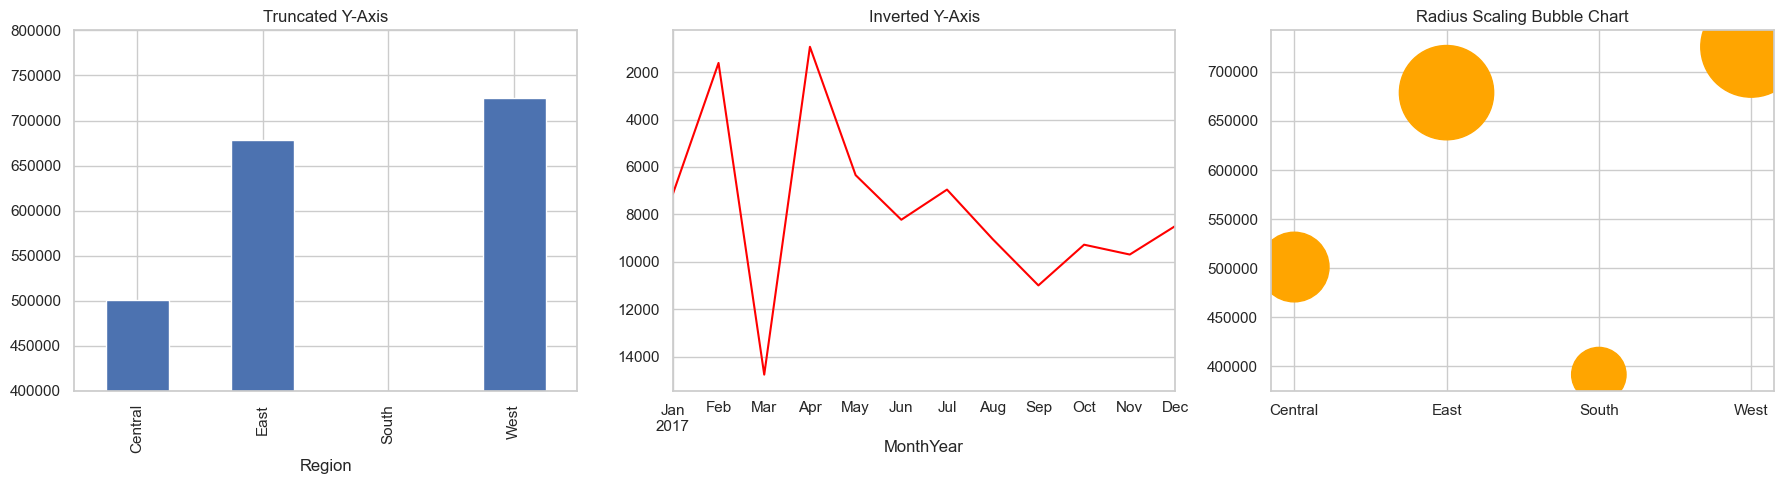

In [23]:
### TASK 5 ###
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

df.groupby('Region')['Sales'].sum().plot(kind = 'bar', ax = axes[0], ylim = (400000, 800000), title = 'Truncated Y-Axis')
monthly_profit.tail(12).plot(kind = 'line', ax = axes[1], color = 'red', title = 'Inverted Y-Axis').invert_yaxis()

region_sales = df.groupby('Region')['Sales'].sum().reset_index()
axes[2].scatter(region_sales['Region'], region_sales['Sales'], s = (region_sales['Sales'] / 10000)**2, color = 'orange')
axes[2].set_title('Radius Scaling Bubble Chart')

plt.tight_layout()
plt.show()

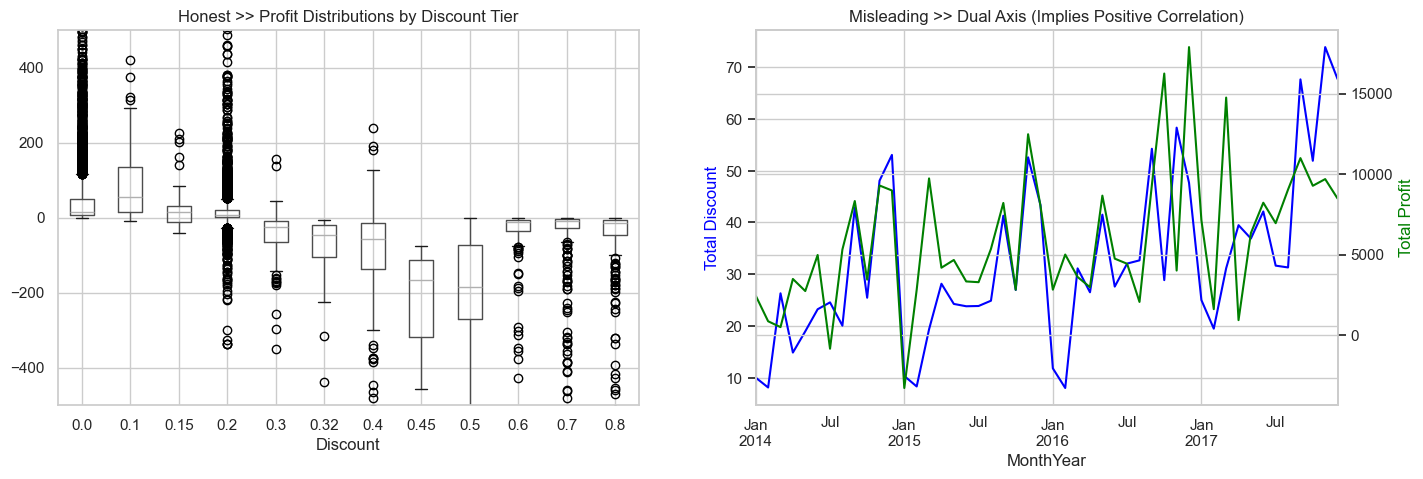

In [25]:
### TASK 6 ###
fig, axes = plt.subplots(1, 2, figsize = (16, 5))

df.boxplot(column = 'Profit', by = 'Discount', ax = axes[0])
axes[0].set_ylim(-500, 500)
axes[0].set_title('Honest >> Profit Distributions by Discount Tier')
plt.suptitle("") 

monthly_agg = df.groupby('MonthYear')[['Discount', 'Profit']].sum()
ax1 = monthly_agg['Discount'].plot(color = 'blue', ax = axes[1], label = 'Total Discount')
ax2 = ax1.twinx() 
monthly_agg['Profit'].plot(color = 'green', ax = ax2, label = 'Total Profit')

axes[1].set_ylabel('Total Discount', color = 'blue')
ax2.set_ylabel('Total Profit', color = 'green')
axes[1].set_title('Misleading >> Dual Axis (Implies Positive Correlation)')

plt.show()